# Flat AB performance comparison

The technical source is a centered **AB 20 flat $f_\nu$ continuum**. All five configurations use the same evaluated atmospheric transmission, continuum and PALACE airglow, with dark sky, airmass 1.1, seeing 0.65 arcsec and MJD 60310.25.

Both X-shooter modes are executed: faint continuum (1.0/0.9/0.9 arcsec, spectral CCD binning by two) and higher resolution (0.8/0.9/0.6 arcsec, unbinned). ZShooter is evaluated with natural seeing and a 0.70 arcsec slit, AO and a 0.33 arcsec slit, and a natural-seeing 0.33 arcsec control. Its selected Zemax prescription and explicit detector offsets are used unchanged.

Native detector pixels are extracted with transparent boxcars. Optical rates are reused for exposure and detector engineering scenarios. The figures distinguish instrumental throughput, extracted fraction, geometric slit resolution, simulated point-source resolution, and sensitivity with or without OH sample selection.

In [1]:
from pathlib import Path
from time import perf_counter
from copy import deepcopy
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.io import fits
from astropy.table import Table
from scipy import sparse
from scipy.ndimage import median_filter
import scopesim as sim
from scopesim.source.source_templates import ab_spectrum
from scopesim.effects import SelectorWheel, SpectralTraceList, SpectralQuantumEfficiency, SurfaceList, TERCurve
from scopesim.effects.electronic import ADConversion, ExposureOutput
from scopesim.utils import from_currsys
from zs_scopesim_tools.helpers import configure_irdb_path, warning_prevent_sync_alt_ra_dec, disable_scopesim_progress_bars, set_scopesim_log_level
from zs_scopesim_tools.comparison import detector_rates, detector_noise, trace_pixel_grid, boxcar_sum, choose_boxcar, limiting_abmag, gaussian_bin_matrix, line_width, select_spectral_samples, trace_line_profiles

workspace = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / 'env/zshooter-stack.toml').exists())
irdb = Path(configure_irdb_path())
output = workspace / 'validation/xshooter/data/comparison'
output.mkdir(parents=True, exist_ok=True)
set_scopesim_log_level('error')
print(sim.__version__, sim.__file__)

0.12.1.dev6 /Users/jibailey/src/scopesim/scopesim/__init__.py


In [2]:
AB_MAG, SEEING, AIRMASS = 20., .65, 1.1
TARGET_R, SAMPLES_PER_FWHM = 1000., 8
SKY_VARIANCE_FACTOR = 2.  # Independent equal-time sky: Var(source - sky) = S + 2(B + D + Vread).
flat_ab = ab_spectrum(mag=AB_MAG)
source = sim.Source(x=[0.], y=[0.], ref=[0], weight=[1.], spectra=[flat_ab])
properties = {'!OBS.airmass': AIRMASS, '!OBS.seeing': SEEING, '!OBS.brightness': 'dark', '!OBS.mjdobs': 60310.25, '!SIM.random.seed': 62419, '!OBS.dit': 1800., '!OBS.ndit': 1}
cases = [
    ('ZS natural .70', 'ZShooter_v2', {'!INST.vis_curr_slit': .7, '!INST.nir_curr_slit': .7}, False),
    ('ZS AO .33', 'ZShooter_v2', {'!INST.vis_curr_slit': .33, '!INST.nir_curr_slit': .33}, True),
    ('ZS natural .33', 'ZShooter_v2', {'!INST.vis_curr_slit': .33, '!INST.nir_curr_slit': .33}, False),
    ('XS faint', 'XSHOOTER', {'!INST.uvb_curr_slit': '1.0', '!INST.vis_curr_slit': '0.9', '!INST.nir_curr_slit': '0.9', '!DET.biny_uvb': 2, '!DET.biny_vis': 2}, False),
    ('XS high', 'XSHOOTER', {'!INST.uvb_curr_slit': '0.8', '!INST.vis_curr_slit': '0.9', '!INST.nir_curr_slit': '0.6', '!DET.biny_uvb': 1, '!DET.biny_vis': 1}, False),
]
atmosphere_names = ('atmo_transmission', 'continuum_emission', 'airglow_and_interline_continuum')
colors = dict(zip([case[0] for case in cases], ['C0', 'C2', 'C4', 'C1', 'C3']))
# These are the parameters of the ESO model that generated the configured traces.
xs_blaze_constant = {}
for arm in ('uvb', 'vis', 'nir'):
    parameters = Table.read(irdb / f'XSHOOTER/calibration/model_{arm}.fits', hdu=1)
    params = dict(zip(np.char.strip(parameters['Parameter_Name']), parameters['Best_Guess']))
    xs_blaze_constant[arm.upper()] = 2*np.sin(np.deg2rad(-params['nug'])) / params['sg'] * 1000
extracted, line_profiles, native_images = {}, {}, {}
timings, line_rows, throughput_rows, noise_rows, saturation_rows, aperture_rows, residual_rows = [], [], [], [], [], [], []

## Rates, independent exposures and extraction

Five-minute cases use one 300 s integration. One-hour cases use two 1800 s integrations for ZShooter and X-shooter CCDs; X-shooter NIR uses twelve independent 300 s integrations in faint mode or eight independent 450 s integrations in high-resolution mode. NDIT is one in each native readout. This keeps independent exposures separate from the NIR driver's internally averaged NDIT product. The configured ESO effective-noise table supplies the NIR noise for each DIT. The initially proposed 600 s high-resolution NIR exposure reached 89,871 electrons in its brightest pixel, above the adopted 89,000-electron linearity limit; 450 s gives headroom.

An equal-time independent sky measurement is subtracted. In accumulated electrons, $V=S+2(B+D+N_{\rm exp}\sigma_r^2)$. The headline exposure is on-source time; a separate equal-time sky costs that much additional observing time before overheads.

Boxcar widths are selected from the expected one-hour current-detector signal and variance, then held fixed across detector alternatives and exposure comparisons. Instrumental throughput is evaluated directly from configured response curves without atmospheric absorption. The source extraction still includes the common atmosphere and finite slit/boxcar losses.

In [3]:
def observe_rates(train, target, name, kind):
    for plane in train.image_planes:
        plane.data.fill(0)
    start = perf_counter()
    with disable_scopesim_progress_bars():
        train.observe(target, update=False)
    elapsed = perf_counter() - start
    timings.append((name, kind, elapsed))
    print(f'{name}: {kind} {elapsed:.1f} s', flush=True)
    return detector_rates(train)

def exposure_settings(name, arms, seconds):
    dit = [300.] * len(arms) if seconds == 300 else [1800.] * len(arms)
    if name == 'XS faint' and seconds == 3600:
        dit[-1] = 300.
    if name == 'XS high' and seconds == 3600:
        dit[-1] = 450.
    settings = {'dit': dit[0], 'ndit': 1}
    for arm, duration in zip(arms, dit):
        settings[f'dit_{arm}'] = duration
        settings[f'ndit_{arm}'] = 1
    return settings, np.array(dit), seconds/np.array(dit)

def extracted_orders(train, name, signal_rates, sky_rates, noises):
    orders = {}
    trace_list, = train.optics_manager.get_all(SpectralTraceList)
    for trace_id, trace in trace_list.spectral_traces.items():
        index, axis, pixels, centers, edges = trace_pixel_grid(train, trace_id)
        midpoint = (edges[0] + edges[-1])/2
        spatial_axis = 'y' if axis == 'x' else 'x'
        aperture = train.trace_detector_coordinates(xi=np.array([-1.5, 1.5])*SEEING*u.arcsec, wavelengths={trace_id: midpoint.reshape(1)})
        max_width = int(np.ceil(np.ptp(aperture[f'detector_{spatial_axis}'].to_value(u.pixel))))
        size = signal_rates[index].shape[0 if axis == 'x' else 1]
        valid = np.flatnonzero((centers >= max_width/2) & (centers < size-max_width/2))
        assert len(valid) and np.all(np.diff(valid) == 1), (name, trace_id)
        first, last = valid[0], valid[-1]
        pixels, centers, edges = pixels[first:last+1], centers[first:last+1], edges[first:last+2]
        dit, dark, readvar, nexp = noises[index]
        widths = choose_boxcar(signal_rates[index]*3600, sky_rates[index]*3600, axis, pixels, centers, max_width, (dark+readvar)*nexp)
        signal = boxcar_sum(signal_rates[index], axis, pixels, centers, widths)
        sky = boxcar_sum(sky_rates[index], axis, pixels, centers, widths)
        orders[trace_id] = {'index': index, 'axis': axis, 'pixels': pixels, 'centers': centers, 'edges': edges, 'widths': widths, 'source_rate': signal, 'sky_rate': sky}
        aperture_rows.append((name, trace_id, widths.min(), widths.max(), signal.sum(), sky.sum()))
    return orders

In [4]:
from zs_scopesim_tools.validation import build_transmission_sanity_data, evaluate_trace_detector_qe

for name, instrument, settings, ao in cases:
    start = perf_counter()
    config = properties | settings
    if instrument == 'ZShooter_v2':
        config.update({'!INST.include_diffuse_emissivity': False, '!ATMO.skycalc_timeout': 60.})
    commands = sim.UserCommands(use_instrument=instrument, set_modes=['SPEC'], properties=config, ignore_effects=['skycalc_atmosphere'] if instrument == 'XSHOOTER' else [])
    warning_prevent_sync_alt_ra_dec(commands)
    if name != 'ZS natural .70':
        for document in commands.yaml_dicts:
            if 'effects' in document:
                document['effects'] = [effect for effect in document['effects'] if effect['name'] not in atmosphere_names]
    train = sim.OpticalTrain(commands)
    if instrument == 'ZShooter_v2':
        train['seeing_psf'].meta['enable_ao'] = ao
    if name == 'ZS natural .70':
        common_atmosphere = [deepcopy(train[effect]) for effect in atmosphere_names]
    else:
        for effect in common_atmosphere:
            train.optics_manager.add_effect(deepcopy(effect))
    timings.append((name, 'setup', perf_counter()-start))
    arms = ('blue', 'green', 'red', 'yj', 'h', 'k') if instrument == 'ZShooter_v2' else ('uvb', 'vis', 'nir')
    trace_list, = train.optics_manager.get_all(SpectralTraceList)
    total_rates = observe_rates(train, source, name, 'source + sky')
    noises = {}
    star_readouts = {}
    for seconds in (300, 3600):
        read_settings, dits, nexp = exposure_settings(name, arms, seconds)
        start = perf_counter()
        readouts = train.readout(roid=0, **read_settings)
        timings.append((name, f'readout {seconds}s case', perf_counter()-start))
        noises[seconds] = []
        for index, readout in enumerate(readouts):
            exptime, dark, readvar = detector_noise(train, index)
            assert exptime == dits[index] == readout[1].header['DIT']
            assert readout[1].header['NDIT'] == 1
            noises[seconds].append((exptime, dark, readvar, nexp[index]))
            noise_rows.append((name, seconds, arms[index], exptime, nexp[index], dark, np.sqrt(readvar)))
            if seconds == 3600:
                filename = output / f'{name.replace(" ", "_")}_star_{index}.fits'
                readout.writeto(filename, overwrite=True)
                star_readouts[index] = filename
    sky_rates = observe_rates(train, None, name, 'sky')
    read_settings, dits, nexp = exposure_settings(name, arms, 3600)
    sky_readouts = train.readout(roid=1, **read_settings)
    signal_rates = [total-sky for total, sky in zip(total_rates, sky_rates)]
    for signal in signal_rates:
        assert signal.min() >= -1e-6*signal.max(), 'Independent observations changed the background.'
    orders = extracted_orders(train, name, signal_rates, sky_rates, noises[3600])
    extracted[name] = orders
    native_images[name] = []
    for index, signal in enumerate(signal_rates):
        filename = output / f'{name.replace(" ", "_")}_source_rate_{index}.npy'
        np.save(filename, signal)
        native_images[name].append(filename)
        saturation_rows.append((name, arms[index], dits[index], total_rates[index].max()*dits[index], sky_rates[index].max()*dits[index]))
    if instrument == 'ZShooter_v2':
        response = build_transmission_sanity_data(train, np.linspace(300, 2500, 50001)*u.nm, component_metadata={'telescope_reflection': {'throughput_group': 'telescope', 'emission_phase': 'pre_disperser'}, 'ir_blocking_filter_selector': {'throughput_group': 'ir_blocking_filter'}})
        qe_selectors = [effect for effect in train.optics_manager.all_effects if effect.meta['name'] == 'detector_qe_selector']
        current_qe, = [effect for effect in qe_selectors if effect.include]
        standard_qe, = [effect for effect in qe_selectors if not effect.include]
        h2rg = SpectralQuantumEfficiency(filename='detector_specs/H2RG_TER.dat', cmds=train.cmds)
    else:
        telescope, = train.optics_manager.get_all(SurfaceList)
    probe_centers = {}
    for trace_id, data in orders.items():
        index = data['index']
        wave = (data['edges'][:-1]+data['edges'][1:])/2
        trace = trace_list.spectral_traces[trace_id]
        channel, order = trace_id.rsplit('_', 1)
        order = int(order)
        if instrument == 'ZShooter_v2':
            spectrograph = trace_list._spectrographs[channel]
            center = spectrograph.central_wave(order).to_value(u.um)
            fsr = spectrograph.fsr(order).to_value(u.um)
            slit = np.ptp(train['slitwheel_selector'].get_effect(index).current_slit.table['y'])
            curves = response['channels'][index]['orders'][trace_id]
            grid = response['wave_nm'].to_value(u.um)
            valid = np.isfinite(curves['instrument'])
            instrument_efficiency = np.interp(wave.value, grid[valid], curves['instrument'][valid])
            total_efficiency = np.interp(wave.value, grid[valid], curves['total_with_telescope_no_slit'][valid])
            alternative = standard_qe.get_effect(index) if index < 3 else h2rg
            new_qe, _ = evaluate_trace_detector_qe(alternative, trace, wave, image_plane=train.image_planes[index])
            old_qe, _ = evaluate_trace_detector_qe(current_qe.get_effect(index), trace, wave, image_plane=train.image_planes[index])
            data['alternative_qe_ratio'] = new_qe/old_qe
        else:
            center = xs_blaze_constant[channel]/order
            fsr = center/order
            slit = np.ptp(train['slits'].get_effect(index).current_slit.table['y'])
            instrument_efficiency = train['order_throughput'].efficiencies[trace_id].throughput(wave).value
            instrument_efficiency *= train['detector_qe'].get_effect(index).throughput(wave).value
            if index == 2:
                instrument_efficiency *= train['nir_order_blocking'].get_effect(index).current_filter.throughput(wave).value
            total_efficiency = instrument_efficiency*telescope.throughput(wave).value
        data['noises'] = {seconds: noises[seconds][index] for seconds in (300, 3600)}
        data['wave'] = wave
        data['slit_arcsec'] = slit
        data['fsr_center_um'], data['fsr_um'] = center, fsr
        data['geometric_R'] = wave.value/(abs(trace.slit_dispersion(wave.value))*slit)
        data['instrument_efficiency'], data['total_efficiency'] = instrument_efficiency, total_efficiency
        atmosphere = train['atmo_transmission'].throughput(wave).value
        incident_rate = (flat_ab(wave).to(u.photon/u.s/u.m**2/u.um)*np.diff(data['edges'])*train.optics_manager.area).to_value(u.photon/u.s)
        primary = abs(wave.value-center) <= fsr/2
        data['extracted_fraction'] = data['source_rate'][primary].sum() / (incident_rate*atmosphere*total_efficiency)[primary].sum()
        peak = np.argmax(instrument_efficiency)
        throughput_rows.append((name, trace_id, wave[peak].value, instrument_efficiency[peak], total_efficiency[peak], data['extracted_fraction']))
        candidates = center + (np.array([.2, .5, .8])-.5)*fsr
        probe_centers[trace_id] = candidates[(candidates > data['edges'][0].value*1.002) & (candidates < data['edges'][-1].value*.998)]
        assert len(probe_centers[trace_id]), (name, trace_id, 'No isolated probe inside detector coverage.')
    # A single-integration stochastic check uses the native gain/averaging effects.
    for index, sky_readout in enumerate(sky_readouts):
        residuals = []
        difference = fits.getdata(star_readouts[index], 1)-sky_readout[1].data
        detector, = train.detector_managers[index]
        for effect in train.optics_manager.detector_effects:
            selected = effect.get_effect(detector.det_id) if isinstance(effect, SelectorWheel) else effect
            if isinstance(selected, ADConversion):
                difference *= selected._get_gain(detector.det_id)
        dit, dark, readvar, count = noises[3600][index]
        for data in orders.values():
            if data['index'] == index:
                observed = boxcar_sum(difference, data['axis'], data['pixels'], data['centers'], data['widths'])
                signal = data['source_rate']*dit
                variance = signal + 2*(data['sky_rate']*dit + data['widths']*(dark+readvar))
                residuals.extend((observed-signal)/np.sqrt(variance))
        residual_rows.append((name, arms[index], len(residuals), np.mean(residuals), np.std(residuals)))
    start = perf_counter()
    profiles = trace_line_profiles(train, orders, probe_centers)
    line_profiles[name] = profiles
    timings.append((name, 'isolated line grid', perf_counter()-start))
    for trace_id, centers in probe_centers.items():
        orders[trace_id]['probe_centers'] = centers
    print(f'{name}: extracted {len(orders)} orders; line probes {timings[-1][2]:.1f} s', flush=True)
    del train, total_rates, sky_rates, signal_rates, readouts, sky_readouts, difference
    gc.collect()

timing_table = pd.DataFrame(timings, columns=['configuration', 'stage', 'seconds'])
noise_table = pd.DataFrame(noise_rows, columns=['configuration', 'on_source_s', 'arm', 'dit_s', 'independent_exposures', 'dark_e_per_integration_pixel', 'effective_read_noise_e'])
throughput_table = pd.DataFrame(throughput_rows, columns=['configuration', 'trace', 'wavelength_um', 'instrument_efficiency', 'telescope_inclusive_efficiency', 'extracted_fraction'])
saturation_table = pd.DataFrame(saturation_rows, columns=['configuration', 'arm', 'dit_s', 'peak_source_plus_background_e', 'peak_background_e'])
residual_table = pd.DataFrame(residual_rows, columns=['configuration', 'arm', 'samples', 'mean_standardized_residual', 'std_standardized_residual'])
for table, filename in [(timing_table, 'timings.csv'), (noise_table, 'exposures.csv'), (throughput_table, 'throughput_peaks.csv'), (saturation_table, 'saturation.csv'), (residual_table, 'noisy_extraction.csv')]:
    table.to_csv(output/filename, index=False)
pd.DataFrame(aperture_rows, columns=['configuration', 'trace', 'min_width_pixel', 'max_width_pixel', 'source_e_s', 'sky_e_s']).to_csv(output/'apertures.csv', index=False)
display(timing_table, saturation_table, residual_table)

ZS natural .70: source + sky 77.2 s
ZS natural .70: sky 74.4 s
ZS natural .70: extracted 125 orders; line probes 19.8 s
ZS AO .33: source + sky 118.6 s
ZS AO .33: sky 114.3 s
ZS AO .33: extracted 125 orders; line probes 28.5 s
ZS natural .33: source + sky 78.1 s
ZS natural .33: sky 77.4 s
ZS natural .33: extracted 125 orders; line probes 17.6 s
XS faint: source + sky 121.5 s
XS faint: sky 119.3 s
XS faint: extracted 43 orders; line probes 18.2 s
XS high: source + sky 107.5 s
XS high: sky 109.4 s
XS high: extracted 43 orders; line probes 20.3 s


,configuration,stage,seconds
0,ZS natural .70,setup,9.290256
1,ZS natural .70,source + sky,77.160392
2,ZS natural .70,readout 300s case,1.378842
3,ZS natural .70,readout 3600s case,1.558350
4,ZS natural .70,sky,74.399020
5,ZS natural .70,isolated line grid,19.792596
6,ZS AO .33,setup,3.968470
7,ZS AO .33,source + sky,118.571770
8,ZS AO .33,readout 300s case,1.266718
9,ZS AO .33,readout 3600s case,1.514788


,configuration,arm,dit_s,peak_source_plus_background_e,peak_background_e
0,ZS natural .70,blue,1800.0,70.186174,20.707759
1,ZS natural .70,green,1800.0,6972.685116,6908.290600
2,ZS natural .70,red,1800.0,12548.160277,12491.794580
3,ZS natural .70,yj,1800.0,104432.425912,104373.095704
4,ZS natural .70,h,1800.0,572092.878898,572033.334540
5,ZS natural .70,k,1800.0,308522.282168,308522.282168
6,ZS AO .33,blue,1800.0,95.037386,14.329719
7,ZS AO .33,green,1800.0,6583.891355,6583.891303
8,ZS AO .33,red,1800.0,11774.367107,11697.161400
9,ZS AO .33,yj,1800.0,95962.177973,95962.177962


,configuration,arm,samples,mean_standardized_residual,std_standardized_residual
0,ZS natural .70,blue,69632,-0.002662,1.000479
1,ZS natural .70,green,61440,0.001846,0.999297
2,ZS natural .70,red,40960,0.006177,1.001103
3,ZS natural .70,yj,46468,0.003877,1.001848
4,ZS natural .70,h,20480,0.012843,0.995336
5,ZS natural .70,k,16384,0.003756,1.011621
6,ZS AO .33,blue,69632,-0.001276,1.000381
7,ZS AO .33,green,61440,-0.008732,1.003791
8,ZS AO .33,red,40960,0.009712,0.998521
9,ZS AO .33,yj,46468,-0.000016,1.001809


## Geometric resolution and simulated line profiles

The probes are at 20%, 50% and 80% of each primary FSR, wherever that location is fully on the detector. Primary FSR is centered on the configured ZShooter echelle wavelength or the grating wavelength in the ESO calibration model; the plotted detector coverage can extend beyond it.

Each order is illuminated separately with intrinsic $R=200{,}000$ lines through its actual effective PSF, finite slit cells, trace projection and detector binning. This avoids accidental blends from another arm's probe wavelengths. These controlled probes exclude atmospheric displacement, throughput and additive backgrounds. The science continuum observations retain those effects. Point-source FWHM and full-slit geometric $R=\lambda/(|d\lambda/d\eta|\,w)$ are separate quantities.

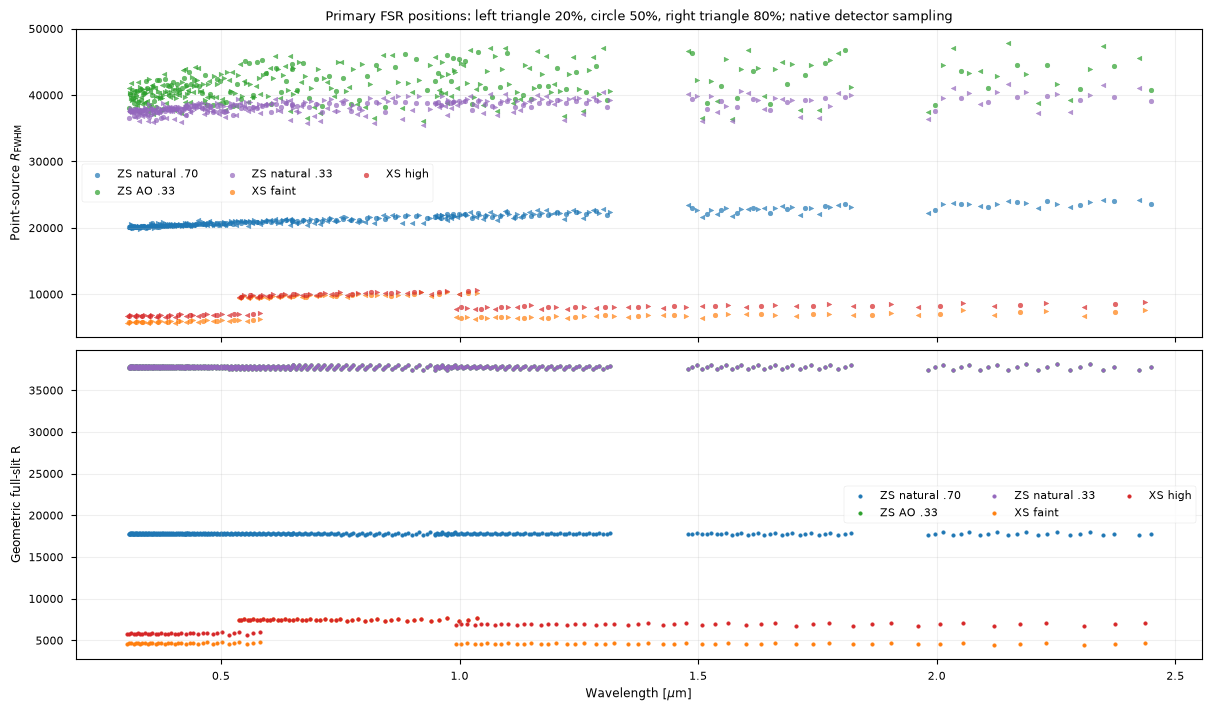

native_R                 geometric_R              
                         min           max           min           max
configuration                                                         
XS faint         5658.645876  10346.256972   4480.721208   7633.396507
XS high          6612.111765  10632.611084   5692.752857   7633.396507
ZS AO .33       36143.747914  47890.612063  37404.550791  38113.431824
ZS natural .33  35417.297149  41733.694213  37404.550791  38113.431824
ZS natural .70  19855.138959  24204.875359  17633.573944  17967.760717

In [5]:
line_rows = []
for name, orders in extracted.items():
    for trace_id, data in orders.items():
        data['line_measurements'] = []
        for center in data['probe_centers']:
            selected = abs(data['wave'].value/center-1) < .0015
            centroid, sigma, fwhm = line_width(data['wave'][selected], line_profiles[name][trace_id][selected])
            fraction = (center-data['fsr_center_um'])/data['fsr_um']+.5
            geometric_R = np.interp(center, data['wave'].value, data['geometric_R'])
            data['line_measurements'].append((center, sigma.value, fwhm.value))
            line_rows.append((name, trace_id, fraction, center, centroid.value, sigma.value, fwhm.value, (centroid/fwhm).value, geometric_R))
line_table = pd.DataFrame(line_rows, columns=['configuration', 'trace', 'fsr_fraction', 'wavelength_um', 'centroid_um', 'sigma_um', 'fwhm_um', 'native_R', 'geometric_R'])
line_table.to_csv(output/'line_widths.csv', index=False)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout='constrained')
for name in extracted:
    data = line_table[line_table.configuration == name]
    for fraction, marker in ((.2, '<'), (.5, 'o'), (.8, '>')):
        selected = data[np.isclose(data.fsr_fraction, fraction)]
        axes[0].scatter(selected.wavelength_um, selected.native_R, s=12, marker=marker, color=colors[name], alpha=.7, label=name if fraction == .5 else None)
    axes[1].scatter(data.wavelength_um, data.geometric_R, s=7, color=colors[name], label=name)
axes[0].set(ylabel=r'Point-source $R_{\rm FWHM}$', title='Primary FSR positions: left triangle 20%, circle 50%, right triangle 80%; native detector sampling')
axes[1].set(ylabel='Geometric full-slit R', xlabel=r'Wavelength [$\mu$m]')
for ax in axes:
    ax.grid(alpha=.2)
    ax.legend(fontsize=8, ncol=3)
fig.savefig(output/'native_resolution.png', dpi=160)
plt.show()
display(line_table.groupby('configuration')[['native_R', 'geometric_R']].agg(['min', 'max']))

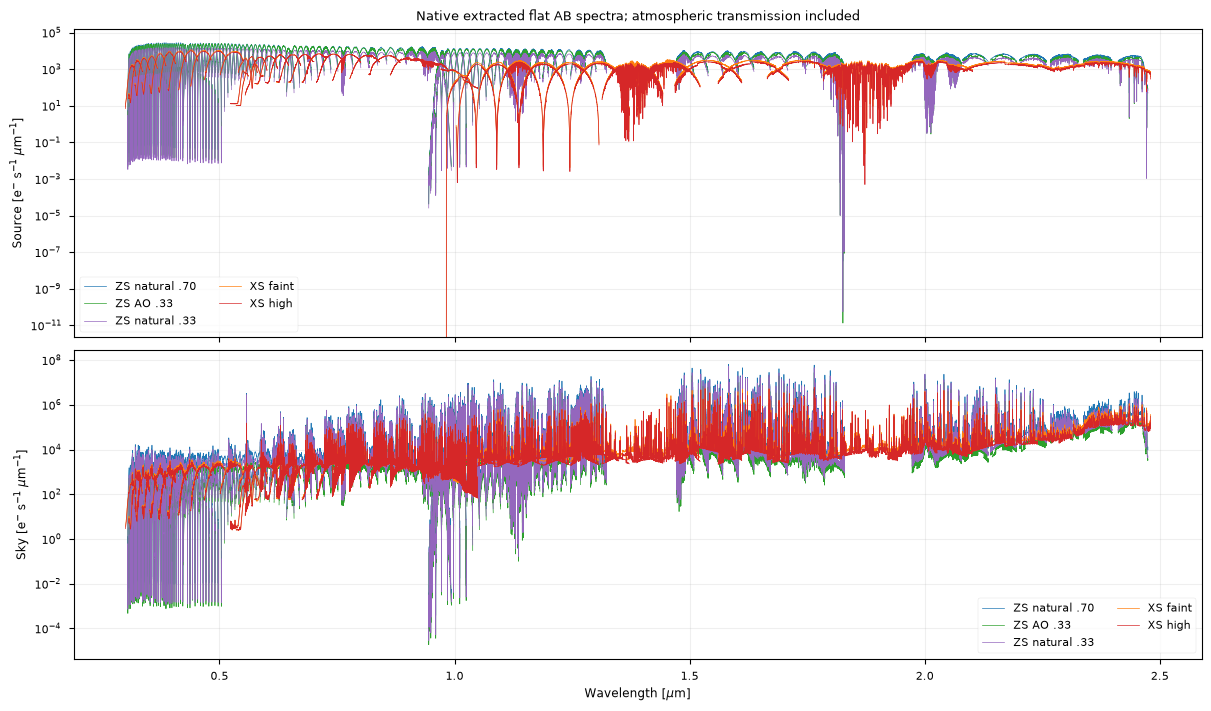

In [6]:
native_parts = []
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout='constrained')
for name in extracted:
    for index, (trace_id, data) in enumerate(extracted[name].items()):
        bin_width = np.diff(data['edges']).to_value(u.um)
        native_parts.append(pd.DataFrame({'configuration': name, 'trace': trace_id, 'wavelength_um': data['wave'].value, 'bin_width_um': bin_width, 'boxcar_width_pixel': data['widths'], 'source_e_s': data['source_rate'], 'sky_e_s': data['sky_rate']}))
        for ax, key in zip(axes, ('source_rate', 'sky_rate')):
            ax.plot(data['wave'].value, data[key]/bin_width, color=colors[name], lw=.5, label=name if index == 0 else None)
axes[0].set(ylabel=r'Source [e$^{-}$ s$^{-1}$ $\mu$m$^{-1}$]', title='Native extracted flat AB spectra; atmospheric transmission included')
axes[1].set(ylabel=r'Sky [e$^{-}$ s$^{-1}$ $\mu$m$^{-1}$]', xlabel=r'Wavelength [$\mu$m]')
for ax in axes:
    ax.set_yscale('log')
    ax.grid(alpha=.2)
    ax.legend(fontsize=8, ncol=2)
pd.concat(native_parts, ignore_index=True).to_csv(output/'native_spectra.csv.gz', index=False)
fig.savefig(output/'native_spectra.png', dpi=160)
plt.show()


## Resolution matching, variance and detector alternatives

The R=1000 spectra use Gaussian redistribution in log wavelength and eight output samples per FWHM. The added kernel variance accounts for the measured native line variance and finite output-bin width. Resolution-element variance is calculated as $(AW)^2V$, where $W$ redistributes native counts and $A$ sums the output samples. This includes the covariance between those samples; summing only their individual variances would be wrong.

The higher-resolution comparison retains X-shooter's unbinned native spectrum and degrades ZShooter to its measured native width as a function of wavelength. Native-bin forecasts use finite wavelength-bin overlaps. Achieved widths are checked with the simulated lines below.

Conventional ZShooter alternatives retain the same optics, spatial aperture and exposure cadence. Source and optical-background rates scale by the actual conventional/current QE ratio. Engineering assumptions are CCD 2.5 electron effective read noise and 0.01 electron/hour/pixel dark current; H2RG 6 electron effective read noise and 23 electron/hour/pixel dark current. The current qCCD/APD specifications come from the configured effects. These effective noise values represent the detector choice without an explicit ramp simulation.

All-sample spectra and sensitivity are the technical comparison. OH-selected intervals use the same ranking and selection rule for both instruments and report retained source flux. Their irregular wavelength response is shown separately.

Sensitivity figures include the common atmosphere. Throughput figures exclude it. Light curves show every calculated sample; heavier median curves are display smoothing only, with their window stated in the caption. The CSV data and line-width measurements remain unsmoothed.

In [12]:
from zs_scopesim_tools.comparison import overlap_bin_matrix

start = perf_counter()
xs_reference = line_table[(line_table.configuration == 'XS high') & np.isclose(line_table.fsr_fraction, .5)].sort_values('wavelength_um')
dense_wave = np.geomspace(.3, 2.5, 100001)
xs_R = np.interp(dense_wave, xs_reference.wavelength_um, xs_reference.native_R)
xs_phase = np.r_[0, np.cumsum((xs_R[:-1]+xs_R[1:])/2*np.diff(np.log(dense_wave)))] * SAMPLES_PER_FWHM
count = int(xs_phase[-1])//SAMPLES_PER_FWHM*SAMPLES_PER_FWHM
matched_edges = np.exp(np.interp(np.arange(count+1), xs_phase, np.log(dense_wave)))*u.um
count = int(np.log(2.5/.3)*TARGET_R*SAMPLES_PER_FWHM)//SAMPLES_PER_FWHM*SAMPLES_PER_FWHM
common_edges = .3*np.exp(np.arange(count+1)/(TARGET_R*SAMPLES_PER_FWHM))*u.um
forecast_parts, width_checks, oh_parts = [], [], []

for name, orders in extracted.items():
    for trace_id, data in orders.items():
        wave = data['wave']
        measurements = np.array(data['line_measurements'])
        native_sigma = np.interp(wave.value, measurements[:, 0], measurements[:, 1]/measurements[:, 0])
        native_R = np.interp(wave.value, measurements[:, 0], measurements[:, 0]/measurements[:, 2])
        phase = np.r_[0, np.cumsum((native_R[:-1]+native_R[1:])/2*np.diff(np.log(wave.value)))]
        native_edges = np.exp(np.interp(np.arange(int(phase[-1])+1), phase, np.log(wave.value)))*u.um
        resolutions = [('native', native_edges, 1), ('R1000', common_edges, SAMPLES_PER_FWHM)]
        if name != 'XS faint':
            resolutions.append(('XS high matched', matched_edges, SAMPLES_PER_FWHM))
        for resolution, edges, samples in resolutions:
            if resolution == 'native' or (resolution == 'XS high matched' and name == 'XS high'):
                operator = overlap_bin_matrix(data['edges'], edges)
                margin = 0.
            else:
                target_R = np.full(len(wave), TARGET_R) if resolution == 'R1000' else np.interp(wave.value, xs_reference.wavelength_um, xs_reference.native_R)
                output_step = 1/(target_R*samples)
                extra_variance = 1/(8*np.log(2)*target_R**2) - native_sigma**2 - output_step**2/12
                assert np.all(extra_variance > 0), (name, trace_id, resolution)
                operator = gaussian_bin_matrix(wave, edges, np.sqrt(extra_variance))
                margin = 6*np.sqrt(extra_variance.max())
            bins = len(edges)-1
            aggregate = sparse.csr_matrix((np.ones(bins), (np.arange(bins)//samples, np.arange(bins))), shape=(bins//samples, bins))
            measurement_operator = aggregate @ operator
            output_edges = edges[::samples]
            output_wave = np.sqrt(output_edges[:-1]*output_edges[1:])
            complete = (output_edges[:-1].value > data['edges'][0].value*np.exp(margin)) & (output_edges[1:].value < data['edges'][-1].value*np.exp(-margin))
            square_operator = measurement_operator.power(2)
            if resolution != 'native' and not (resolution == 'XS high matched' and name == 'XS high'):
                center = measurements[np.argmin(abs(measurements[:, 0]-data['fsr_center_um'])), 0]
                isolated = line_profiles[name][trace_id].copy()
                isolated[abs(wave.value/center-1) > .0015] = 0
                profile = operator @ isolated
                bin_wave = np.sqrt(edges[:-1]*edges[1:])
                near = abs(bin_wave.value/center-1) < .004
                measured_center, sigma, fwhm = line_width(bin_wave[near], profile[near])
                requested = TARGET_R if resolution == 'R1000' else np.interp(center, xs_reference.wavelength_um, xs_reference.native_R)
                width_checks.append((name, trace_id, resolution, center, requested, (measured_center/fwhm).value))
            for seconds in (300, 3600):
                dit, dark, readvar, nexp = data['noises'][seconds]
                detector_cases = ['current', 'conventional'] if name.startswith('ZS') else ['current']
                for detector_case in detector_cases:
                    if detector_case == 'conventional':
                        ratio = data['alternative_qe_ratio']
                        dark_total = seconds*(2.0 if data['index'] < 3 else 23.)/3600
                        read_total = nexp*(2.5 if data['index'] < 3 else 6.)**2
                    else:
                        ratio, dark_total, read_total = 1., dark*nexp, readvar*nexp
                    source_native = data['source_rate']*seconds*ratio
                    sky_native = data['sky_rate']*seconds*ratio
                    signal = measurement_operator @ source_native
                    source_variance = square_operator @ source_native
                    sky_variance = 2*(square_operator @ sky_native)
                    dark_variance = 2*dark_total*(square_operator @ data['widths'])
                    read_variance = 2*read_total*(square_operator @ data['widths'])
                    variance_background = sky_variance+dark_variance+read_variance
                    keep = complete & (signal > 0) & (variance_background > 0)
                    limit = limiting_abmag(signal[keep], source_variance[keep], variance_background[keep], AB_MAG)
                    amplitude = 10**((AB_MAG-limit)/2.5)
                    forecast_parts.append(pd.DataFrame({'configuration': name, 'trace': trace_id, 'resolution': resolution, 'on_source_s': seconds, 'detector': detector_case, 'element': np.flatnonzero(keep), 'wavelength_um': output_wave.value[keep], 'limiting_AB_5sigma': limit, 'source_e_AB20': signal[keep], 'source_variance_at_limit_e2': source_variance[keep]*amplitude, 'sky_variance_e2': sky_variance[keep], 'dark_variance_e2': dark_variance[keep], 'read_variance_e2': read_variance[keep]}))
                    if resolution == 'R1000' and seconds == 3600 and detector_case == 'current':
                        # Save one complete covariance example per configuration.
                        if trace_id == next(iter(orders)):
                            covariance = operator.multiply(source_native+2*(sky_native+data['widths']*(dark_total+read_total))) @ operator.T
                            sparse.save_npz(output/f'{name.replace(" ", "_")}_covariance_example.npz', covariance)
                        for element in np.flatnonzero(complete):
                            selected = (wave >= output_edges[element]) & (wave < output_edges[element+1])
                            s = source_native[selected]
                            v = 2*(sky_native[selected]+data['widths'][selected]*(dark_total+read_total))
                            if len(s) < 2 or np.any(s <= 0):
                                continue
                            retained, selected_limit = select_spectral_samples(s, v, AB_MAG)
                            all_limit = limiting_abmag(s.sum(), s.sum(), v.sum(), AB_MAG)
                            oh_parts.append((name, trace_id, output_wave[element].value, all_limit, selected_limit, s[retained].sum()/s.sum(), len(retained), len(s)))

forecasts = pd.concat(forecast_parts, ignore_index=True)
forecasts.to_csv(output/'sensitivity.csv.gz', index=False)
common_lines = pd.DataFrame(width_checks, columns=['configuration', 'trace', 'resolution', 'wavelength_um', 'target_R', 'achieved_R'])
common_lines.to_csv(output/'matched_line_widths.csv', index=False)
oh_table = pd.DataFrame(oh_parts, columns=['configuration', 'trace', 'wavelength_um', 'all_sample_m5', 'selected_m5', 'retained_source_fraction', 'samples_kept', 'samples_available'])
oh_table.to_csv(output/'oh_selection.csv', index=False)
print(f'Extraction, resolution matching and all detector/exposure forecasts: {perf_counter()-start:.1f} s')
display(common_lines.groupby(['configuration', 'resolution'])[['target_R', 'achieved_R']].agg(['min', 'max']))

Extraction, resolution matching and all detector/exposure forecasts: 78.6 s


target_R                 achieved_R  \
                                        min           max          min   
configuration  resolution                                                
XS faint       R1000            1000.000000   1000.000000   989.483781   
XS high        R1000            1000.000000   1000.000000   989.476838   
ZS AO .33      R1000            1000.000000   1000.000000   989.417780   
               XS high matched  6702.029331  10373.524083  6644.021215   
ZS natural .33 R1000            1000.000000   1000.000000   989.411131   
               XS high matched  6702.029331  10373.524083  6647.661671   
ZS natural .70 R1000            1000.000000   1000.000000   989.415001   
               XS high matched  6702.029331  10373.524083  6643.678700   

                                              
                                         max  
configuration  resolution                     
XS faint       R1000              999.912965  
XS high        R1000              999.919782  
ZS AO .33      R1000              999.986609  
               XS high matched  10299.368748  
ZS natural .33 R1000              999.954983  
               XS high matched  10296.103306  
ZS natural .70 R1000              999.980195  
               XS high matched  10266.509296

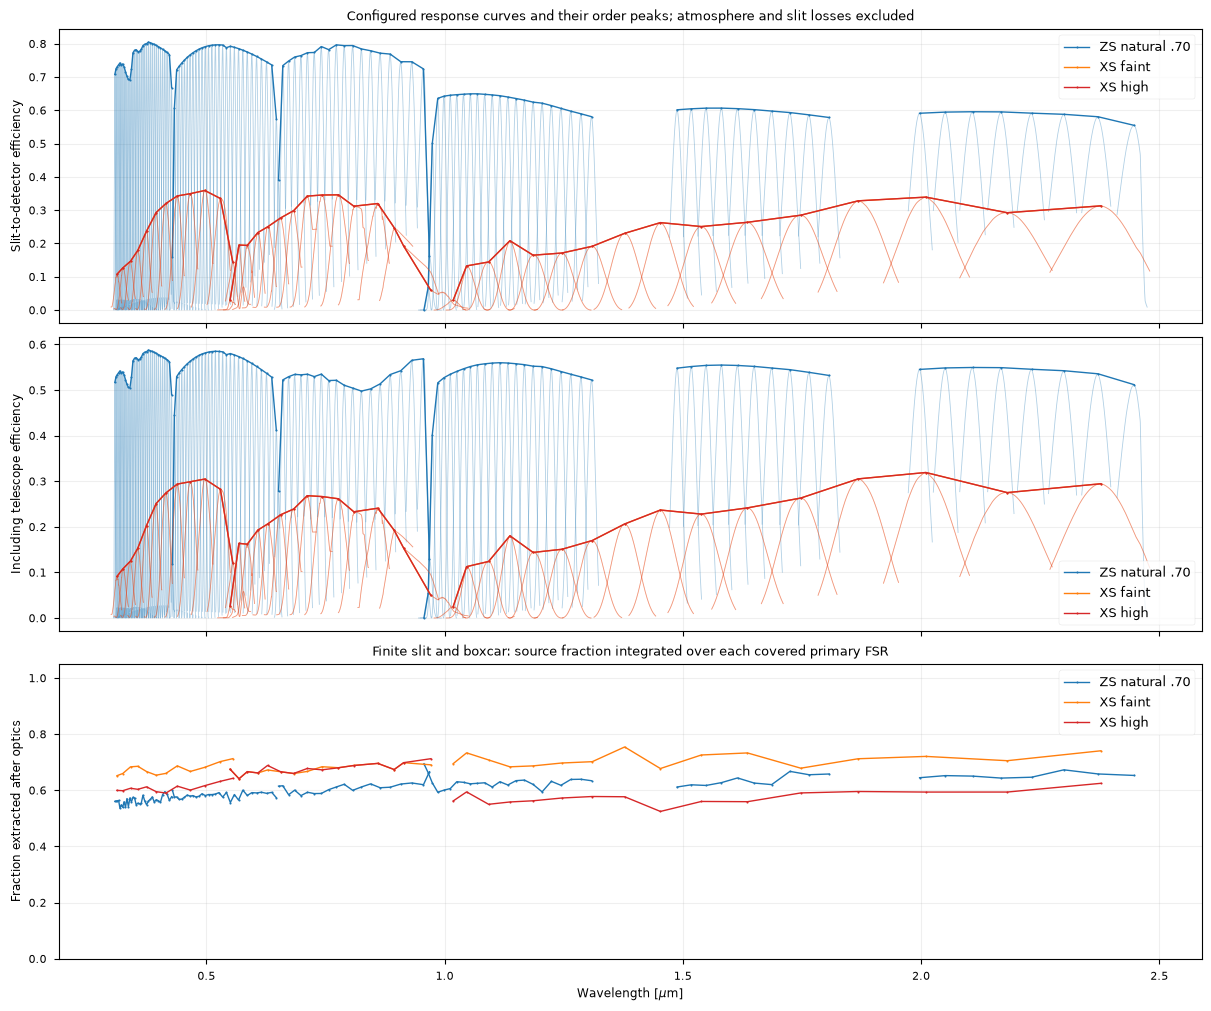

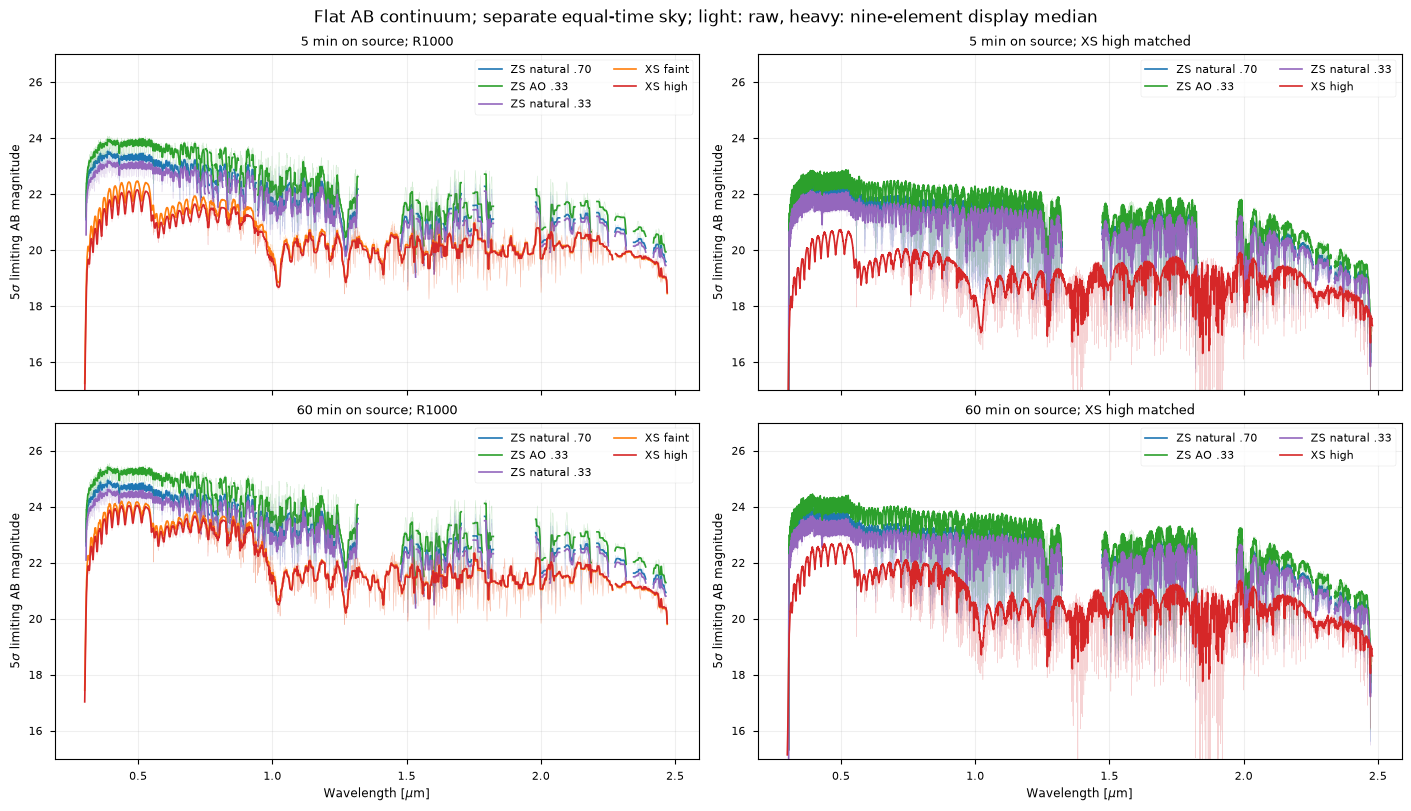

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True, layout='constrained')
for name in ('ZS natural .70', 'XS faint', 'XS high'):
    for trace_id, data in extracted[name].items():
        label = name if trace_id == next(iter(extracted[name])) else None
        axes[0].plot(data['wave'].value, data['instrument_efficiency'], color=colors[name], lw=.6, alpha=.35)
        axes[1].plot(data['wave'].value, data['total_efficiency'], color=colors[name], lw=.6, alpha=.35)
    peaks = throughput_table[throughput_table.configuration == name].sort_values('wavelength_um')
    for group_index, (_, channel_peaks) in enumerate(peaks.groupby(peaks.trace.str.rsplit('_', n=1).str[0], sort=False)):
        for ax, column in zip(axes, ('instrument_efficiency', 'telescope_inclusive_efficiency', 'extracted_fraction')):
            ax.plot(channel_peaks.wavelength_um, channel_peaks[column], '.-', ms=3, lw=1, color=colors[name], label=name if group_index == 0 else None)
axes[0].set(ylabel='Slit-to-detector efficiency', title='Configured response curves and their order peaks; atmosphere and slit losses excluded')
axes[1].set(ylabel='Including telescope efficiency')
axes[2].set(ylabel='Fraction extracted after optics', xlabel=r'Wavelength [$\mu$m]', ylim=(0, 1.05), title='Finite slit and boxcar: source fraction integrated over each covered primary FSR')
for ax in axes:
    ax.grid(alpha=.2)
    ax.legend(fontsize=9)
fig.savefig(output/'instrumental_throughput.png', dpi=160)
plt.show()

common_forecasts = forecasts[forecasts.resolution != 'native']
keys = ['configuration', 'resolution', 'on_source_s', 'detector', 'element']
best = common_forecasts.loc[common_forecasts.groupby(keys).limiting_AB_5sigma.idxmax()].copy()
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, layout='constrained')
for row, seconds in enumerate((300, 3600)):
    for column, resolution in enumerate(('R1000', 'XS high matched')):
        ax = axes[row, column]
        for name in extracted:
            if resolution == 'XS high matched' and name == 'XS faint':
                continue
            data = best[(best.configuration == name) & (best.resolution == resolution) & (best.on_source_s == seconds) & (best.detector == 'current')].sort_values('element')
            for group, segment in data.groupby((data.element.diff() > 1).cumsum()):
                ax.plot(segment.wavelength_um, segment.limiting_AB_5sigma, color=colors[name], lw=.4, alpha=.2)
                ax.plot(segment.wavelength_um, median_filter(segment.limiting_AB_5sigma, size=9, mode='nearest'), color=colors[name], lw=1.2, label=name if group == 0 else None)
        ax.set(title=f'{seconds/60:g} min on source; {resolution}', ylabel=r'$5\sigma$ limiting AB magnitude', ylim=(15, 27))
        ax.grid(alpha=.2)
        ax.legend(fontsize=8, ncol=2)
for ax in axes[-1]:
    ax.set_xlabel(r'Wavelength [$\mu$m]')
fig.suptitle('Flat AB continuum; separate equal-time sky; light: raw, heavy: nine-element display median')
fig.savefig(output/'flat_ab_comparison.png', dpi=160)
plt.show()

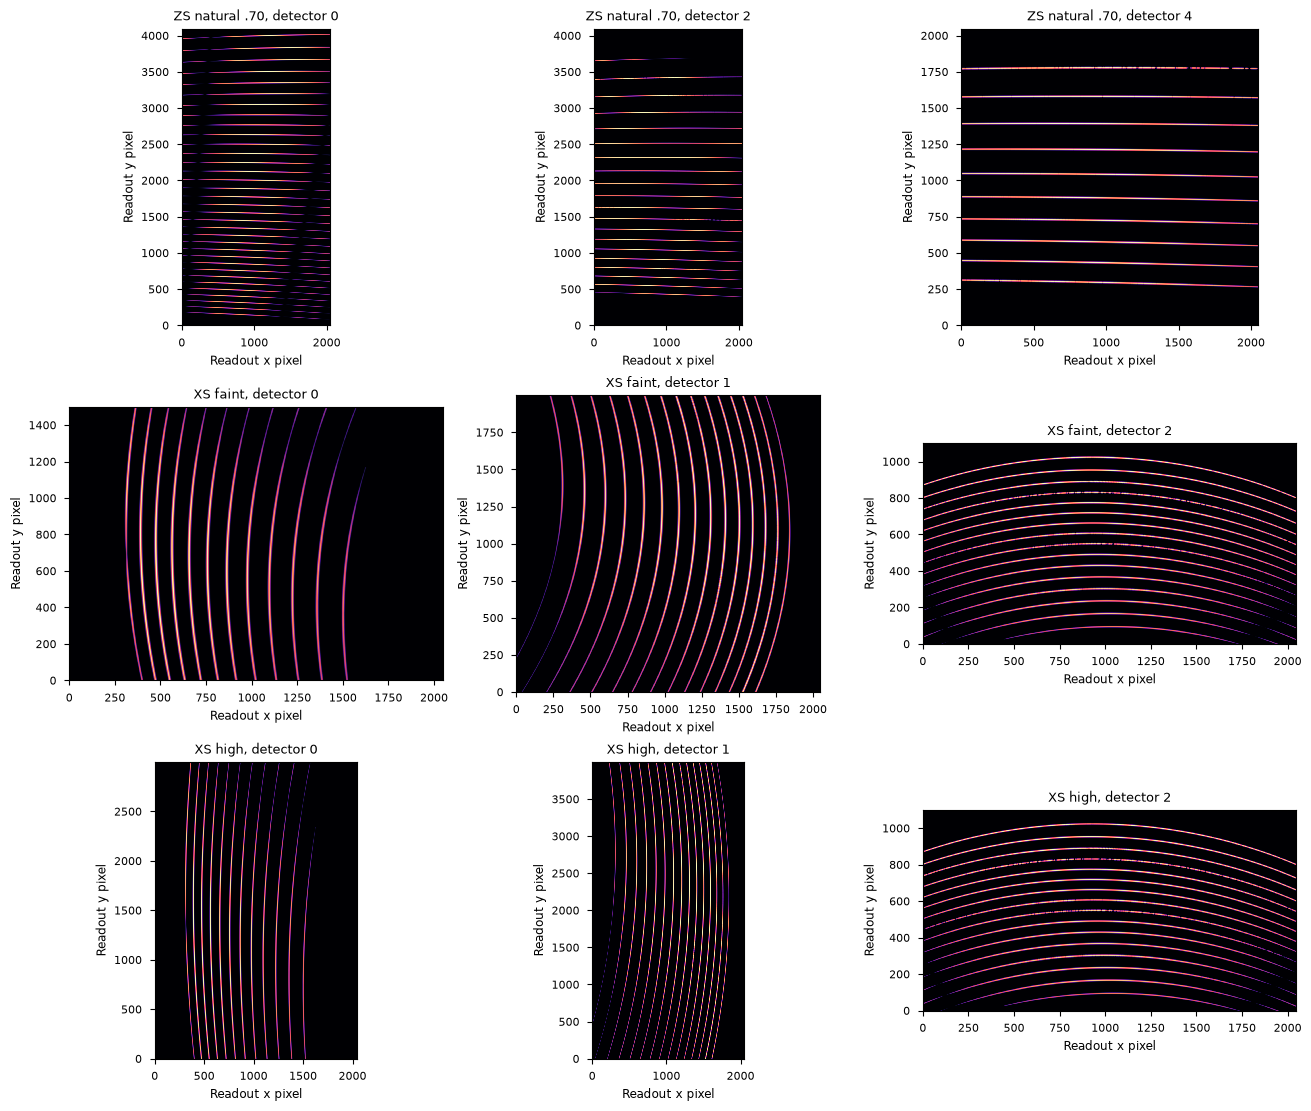

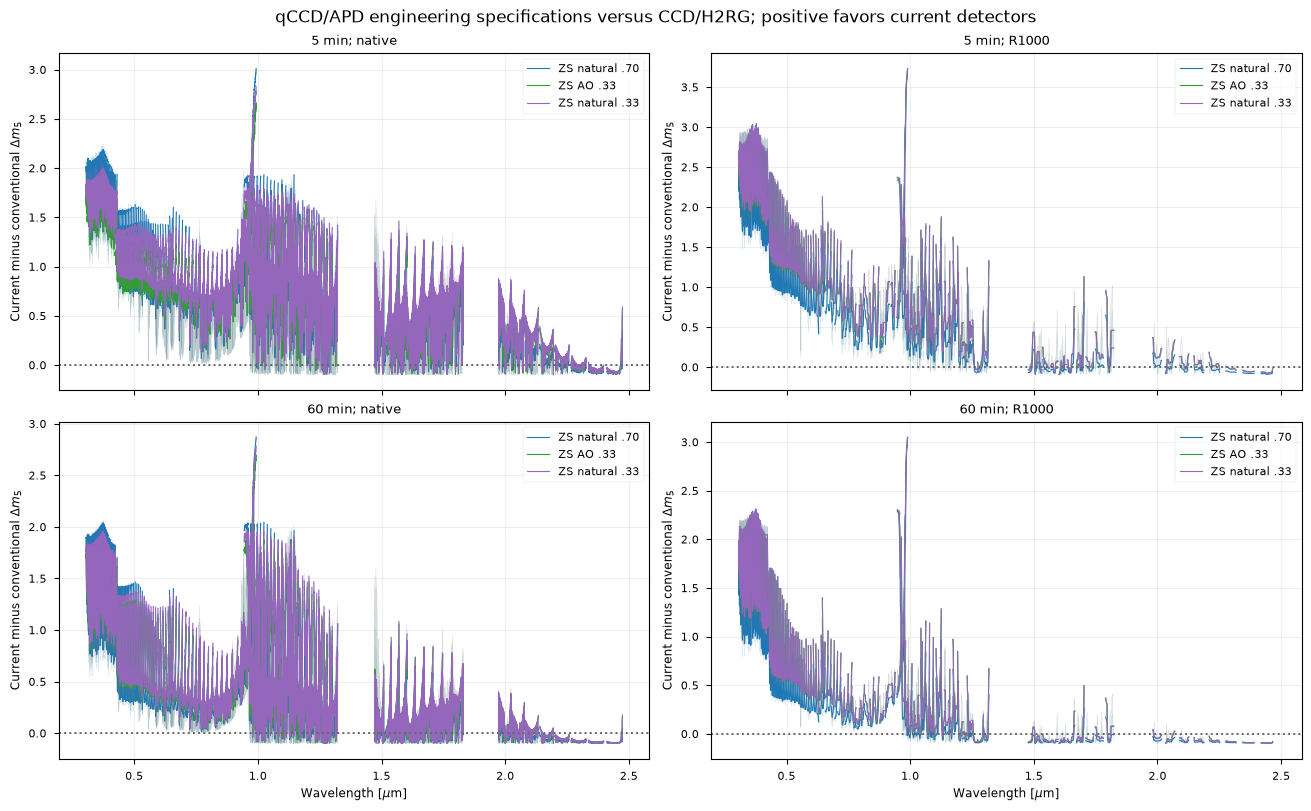

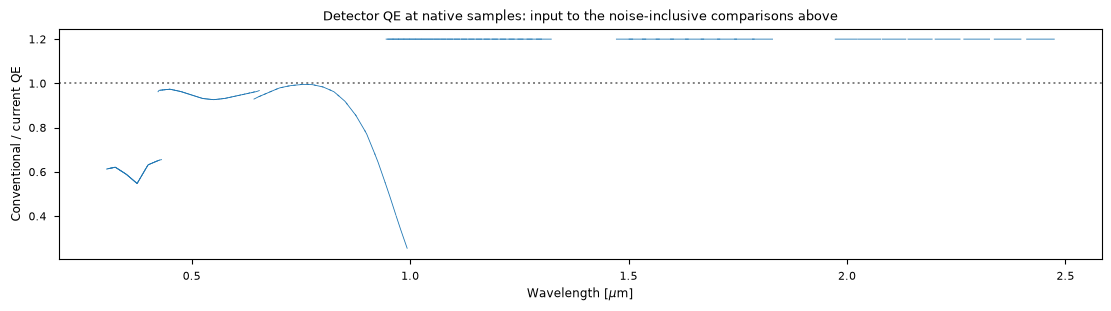

In [14]:
fig, axes = plt.subplots(3, 3, figsize=(13, 11), layout='constrained')
for row, name in enumerate(('ZS natural .70', 'XS faint', 'XS high')):
    detectors = (0, 2, 4) if name.startswith('ZS') else (0, 1, 2)
    for ax, index in zip(axes[row], detectors):
        source_image = np.load(native_images[name][index], mmap_mode='r')
        scale = np.percentile(source_image[source_image > 0], 75)
        ax.imshow(np.arcsinh(source_image/scale), origin='lower', cmap='magma', aspect='equal', interpolation='nearest')
        ax.set(title=f'{name}, detector {index}', xlabel='Readout x pixel', ylabel='Readout y pixel')
fig.savefig(output/'native_frames.png', dpi=150)
plt.show()

# The ratio is an input diagnostic; limiting magnitude includes sky, dark and effective read noise.
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, layout='constrained')
join_keys = ['configuration', 'trace', 'resolution', 'on_source_s', 'element']
current = forecasts[(forecasts.configuration.str.startswith('ZS')) & (forecasts.detector == 'current')]
conventional = forecasts[(forecasts.configuration.str.startswith('ZS')) & (forecasts.detector == 'conventional')]
trade = current.merge(conventional, on=join_keys, suffixes=('_current', '_conventional'))
trade['gain_mag'] = trade.limiting_AB_5sigma_current-trade.limiting_AB_5sigma_conventional
trade.to_csv(output/'detector_trade.csv.gz', index=False)
for row, seconds in enumerate((300, 3600)):
    for column, resolution in enumerate(('native', 'R1000')):
        ax = axes[row, column]
        for name in ('ZS natural .70', 'ZS AO .33', 'ZS natural .33'):
            data = trade[(trade.configuration == name) & (trade.on_source_s == seconds) & (trade.resolution == resolution)]
            for index, (trace_id, segment) in enumerate(data.groupby('trace', sort=False)):
                segment = segment.sort_values('wavelength_um_current')
                ax.plot(segment.wavelength_um_current, segment.gain_mag, color=colors[name], alpha=.15, lw=.4)
                ax.plot(segment.wavelength_um_current, median_filter(segment.gain_mag, size=9, mode='nearest'), color=colors[name], lw=.8, label=name if index == 0 else None)
        ax.axhline(0, color='.4', ls=':')
        ax.set(title=f'{seconds/60:g} min; {resolution}', ylabel=r'Current minus conventional $\Delta m_5$')
        ax.grid(alpha=.2)
        ax.legend(fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel(r'Wavelength [$\mu$m]')
fig.suptitle('qCCD/APD engineering specifications versus CCD/H2RG; positive favors current detectors')
fig.savefig(output/'detector_trade.png', dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(11, 3), layout='constrained')
for trace_id, data in extracted['ZS natural .70'].items():
    ax.plot(data['wave'].value, data['alternative_qe_ratio'], color='C0', lw=.6)
ax.axhline(1, color='.5', ls=':')
ax.set(xlabel=r'Wavelength [$\mu$m]', ylabel='Conventional / current QE', title='Detector QE at native samples: input to the noise-inclusive comparisons above')
fig.savefig(output/'detector_qe_ratio.png', dpi=160)
plt.show()


## OH selection and detector noise budgets

The OH calculation selects native samples within intervals of width $\Delta\log\lambda=1/1000$ using expected signal/background variance and the same five-sigma objective in every configuration. The gain is relative to all native samples in that same interval. The retained source fraction records its cost. These selected intervals have an irregular spectral response; they are not the Gaussian R=1000 spectra above.

Detector-budget panels show fractions of total variance **at the limiting magnitude**, where source Poisson noise must be included. QE alone cannot predict the detector trade, particularly in short exposures or after changing the slit and extraction footprint.

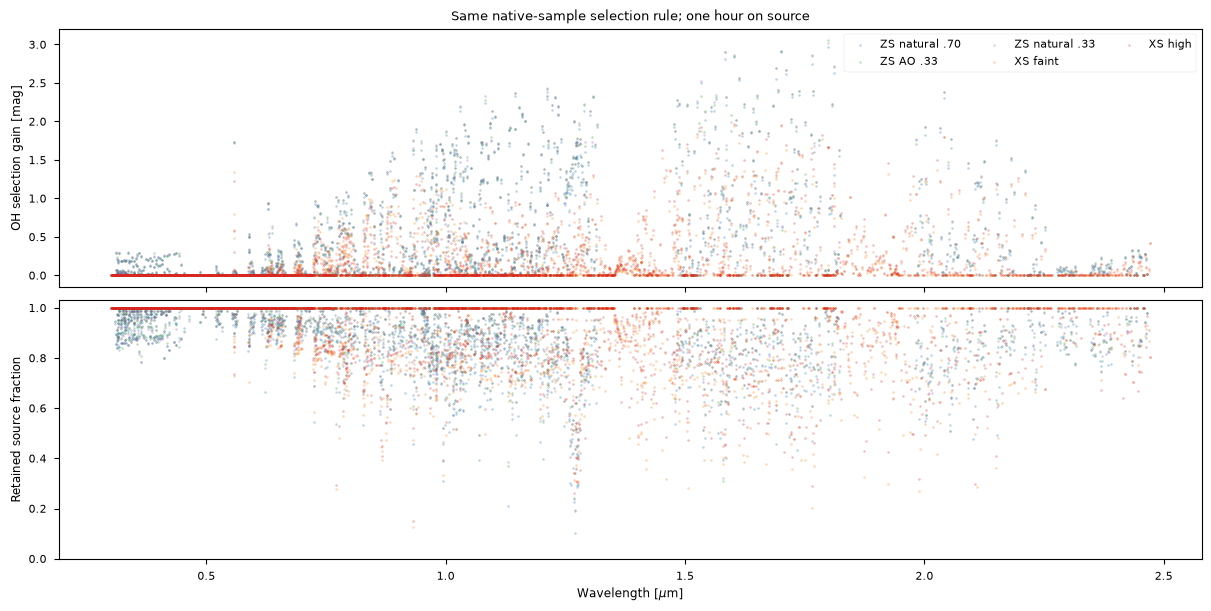

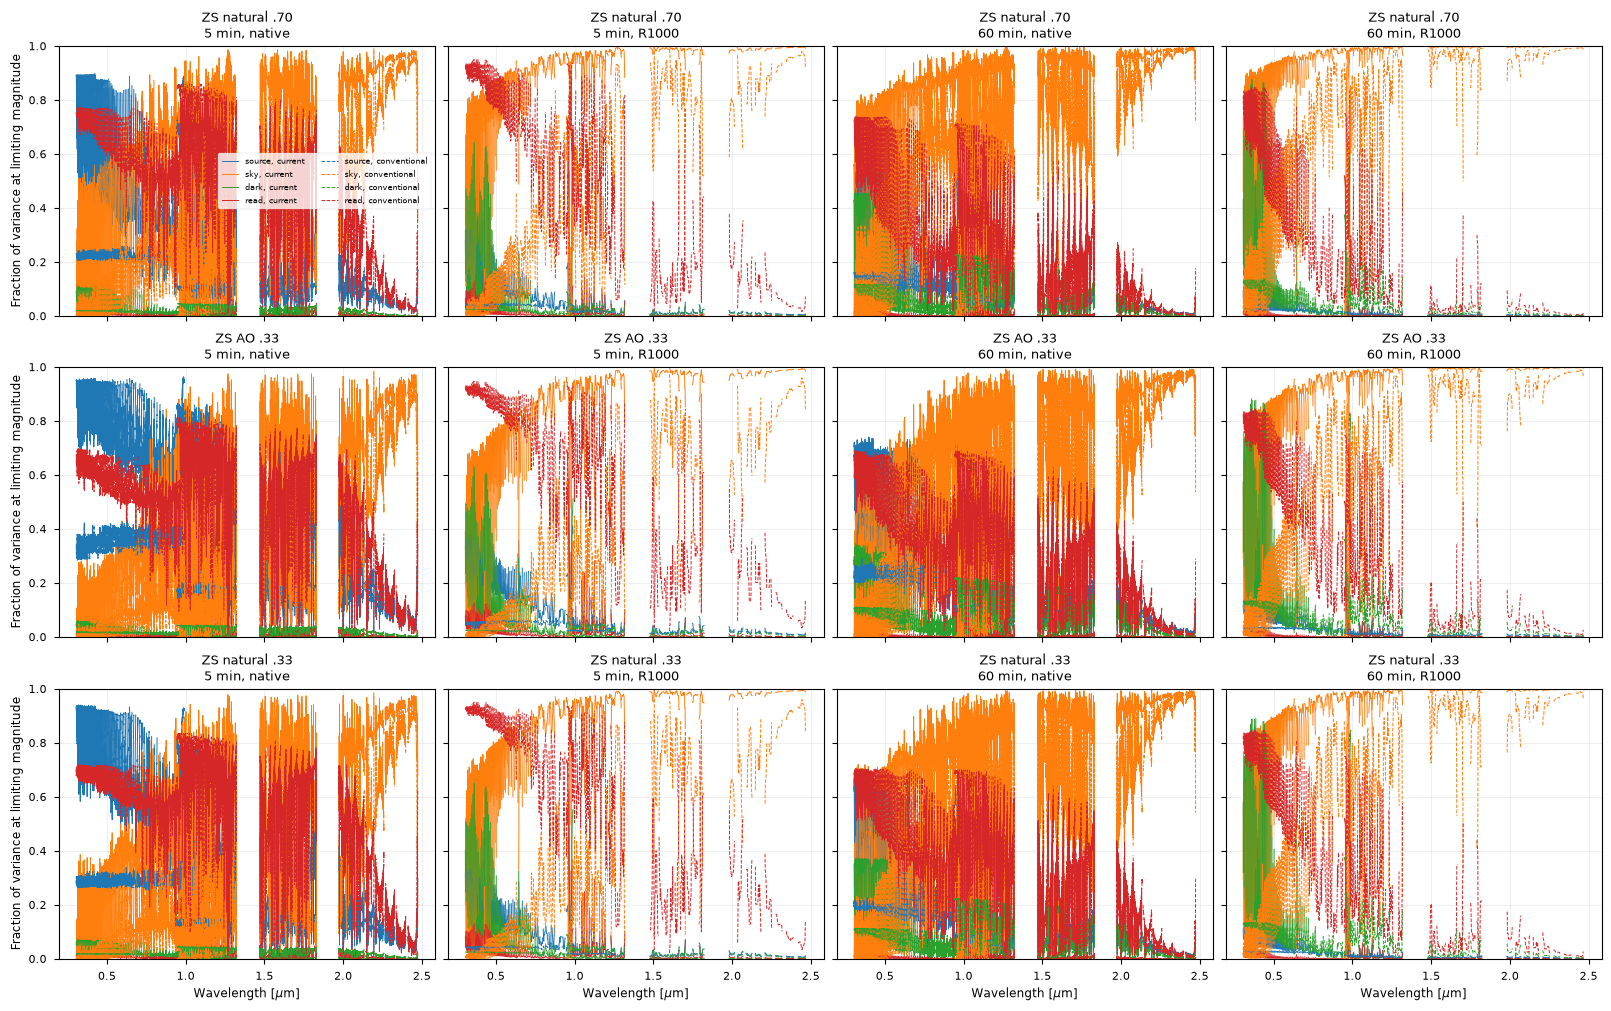

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, layout='constrained')
for name in extracted:
    data = oh_table[oh_table.configuration == name]
    axes[0].scatter(data.wavelength_um, data.selected_m5-data.all_sample_m5, s=2, alpha=.3, color=colors[name], label=name)
    axes[1].scatter(data.wavelength_um, data.retained_source_fraction, s=2, alpha=.3, color=colors[name])
axes[0].set(ylabel='OH selection gain [mag]', title='Same native-sample selection rule; one hour on source')
axes[1].set(ylabel='Retained source fraction', xlabel=r'Wavelength [$\mu$m]', ylim=(0, 1.03))
axes[0].legend(fontsize=8, ncol=3)
fig.savefig(output/'oh_selection.png', dpi=150)
plt.show()

variance_columns = ['source_variance_at_limit_e2', 'sky_variance_e2', 'dark_variance_e2', 'read_variance_e2']
fig, axes = plt.subplots(3, 4, figsize=(16, 10), sharex=True, sharey=True, layout='constrained')
for row, name in enumerate(('ZS natural .70', 'ZS AO .33', 'ZS natural .33')):
    for column, (seconds, resolution) in enumerate(((300, 'native'), (300, 'R1000'), (3600, 'native'), (3600, 'R1000'))):
        ax = axes[row, column]
        selected = trade[(trade.configuration == name) & (trade.on_source_s == seconds) & (trade.resolution == resolution)]
        for detector_case, style in (('current', '-'), ('conventional', '--')):
            columns = [quantity+'_'+detector_case for quantity in variance_columns]
            for trace_index, (_, segment) in enumerate(selected.groupby('trace', sort=False)):
                total = segment[columns].sum(axis=1)
                for color, quantity, label in zip(('C0', 'C1', 'C2', 'C3'), columns, ('source', 'sky', 'dark', 'read')):
                    fraction = segment[quantity]/total
                    ax.plot(segment.wavelength_um_current, median_filter(fraction, size=9, mode='nearest'), style, color=color, lw=.7, label=f'{label}, {detector_case}' if row == column == trace_index == 0 else None)
        ax.set(title=f'{name}\n{seconds/60:g} min, {resolution}', ylim=(0, 1))
        ax.grid(alpha=.2)
axes[0, 0].legend(fontsize=6, ncol=2)
for ax in axes[-1]:
    ax.set_xlabel(r'Wavelength [$\mu$m]')
for ax in axes[:, 0]:
    ax.set_ylabel('Fraction of variance at limiting magnitude')
fig.savefig(output/'detector_noise_budget.png', dpi=150)
plt.show()

## Science context

The flat AB source remains the technical reference. The existing [kilonova source notebook](01_Kilonovae.ipynb) and [X-shooter companion](01_Kilonovae_XSHOOTER.ipynb) supply secondary color and transient context. A G5V template can be observed with the same five configurations. Those structured spectra need their actual spectral normalization and line recovery assessed; their apparent color should not redefine the flat-AB sensitivity curve.

The geometric ZShooter model retains the selected Zemax rulings, CX angles, rotations and explicit detector translations. Its separable grating approximation remains deliberate. X-shooter's trace geometry and optical broadening use the documented ESO calibration inputs. Shared numerical convergence and independent throughput/sensitivity evidence are distinguished in the [validation report](../docs/xshooter-validation.md).

## Native noise check and measured output resolution

The native source-minus-independent-sky residuals use the configured gain and one integration's noise. The exposure forecast then sums the stated number of independent integrations. Their standardized mean should be close to zero and their standard deviation close to one. Bright OH and thermal peaks are checked in electrons **per integration**, before using the NIR cadence.

The following table compares requested and measured degraded line FWHM. It is the check on what the delivered spectral resolution actually is; plot smoothing is absent from this measurement.

,configuration,arm,samples,mean_standardized_residual,std_standardized_residual
0,ZS natural .70,blue,69632,-0.002662,1.000479
1,ZS natural .70,green,61440,0.001846,0.999297
2,ZS natural .70,red,40960,0.006177,1.001103
3,ZS natural .70,yj,46468,0.003877,1.001848
4,ZS natural .70,h,20480,0.012843,0.995336
5,ZS natural .70,k,16384,0.003756,1.011621
6,ZS AO .33,blue,69632,-0.001276,1.000381
7,ZS AO .33,green,61440,-0.008732,1.003791
8,ZS AO .33,red,40960,0.009712,0.998521
9,ZS AO .33,yj,46468,-0.000016,1.001809


,configuration,arm,dit_s,peak_source_plus_background_e,peak_background_e,fraction_of_89000e_limit
20,XS faint,nir,300.0,46025.619445,46025.619444,0.517142
23,XS high,nir,450.0,67403.518081,67403.518081,0.757343


min       max
configuration  resolution                         
XS faint       R1000            0.000087  0.010628
XS high        R1000            0.000080  0.010635
ZS AO .33      R1000            0.000013  0.010695
               XS high matched  0.000132  0.010599
ZS natural .33 R1000            0.000045  0.010702
               XS high matched  0.000115  0.010762
ZS natural .70 R1000            0.000020  0.010698
               XS high matched  0.000816  0.013404

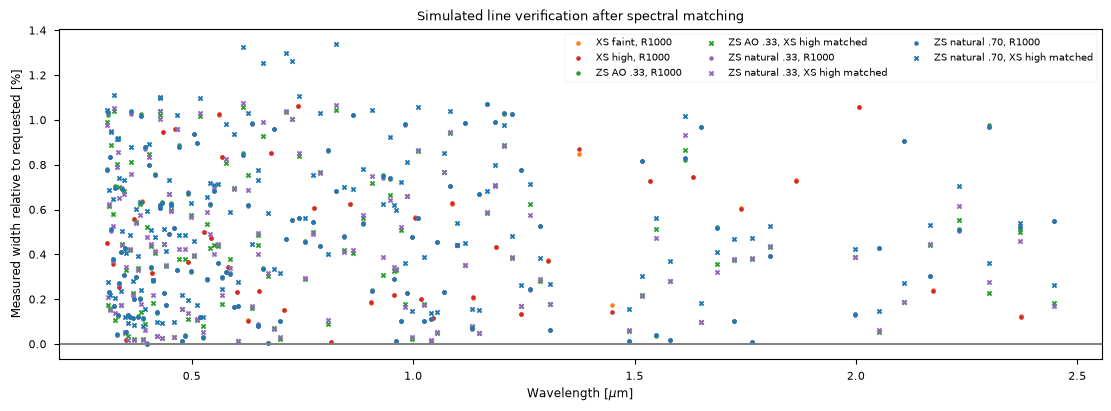

In [16]:
display(residual_table)
assert (abs(residual_table.mean_standardized_residual)*np.sqrt(residual_table.samples) < 4).all()
assert (abs(residual_table.std_standardized_residual-1) < .025).all()
nir_peaks = saturation_table[(saturation_table.configuration.str.startswith('XS')) & (saturation_table.arm == 'nir')]
display(nir_peaks.assign(fraction_of_89000e_limit=nir_peaks.peak_source_plus_background_e/89000))
assert (nir_peaks.peak_source_plus_background_e < 89000).all(), 'Revise NIR DIT before adopting this cadence.'
common_lines['fractional_width_error'] = common_lines.target_R/common_lines.achieved_R-1
assert common_lines.fractional_width_error.abs().max() < .02
display(common_lines.groupby(['configuration', 'resolution']).fractional_width_error.agg(['min', 'max']))
fig, ax = plt.subplots(figsize=(11, 4), layout='constrained')
for (name, resolution), segment in common_lines.groupby(['configuration', 'resolution']):
    ax.scatter(segment.wavelength_um, 100*segment.fractional_width_error, s=9, color=colors[name], marker='o' if resolution == 'R1000' else 'x', label=f'{name}, {resolution}')
ax.axhline(0, color='.5')
ax.set(xlabel=r'Wavelength [$\mu$m]', ylabel='Measured width relative to requested [%]', title='Simulated line verification after spectral matching')
ax.legend(fontsize=7, ncol=3)
fig.savefig(output/'matched_resolution_check.png', dpi=160)
plt.show()